In [1]:

import pandas as pd

# Load our four datasets

plant1_generation = pd.read_csv("Plant_1_Generation_Data.csv")
plant1_weather = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")

plant2_generation = pd.read_csv("Plant_2_Generation_Data.csv")
plant2_weather = pd.read_csv("Plant_2_Weather_Sensor_Data.csv")

print("All four datasets loaded successfully!")


All four datasets loaded successfully!


In [2]:

# Display the first five rows
plant1_generation.head()


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [3]:

# Find the number of rows and columns

print("Plant 1 Generation:", plant1_generation.shape)
print("Plant 1 Weather:", plant1_weather.shape)

print("Plant 2 Generation:", plant2_generation.shape)
print("Plant 2 Weather:", plant2_weather.shape)


Plant 1 Generation: (68778, 7)
Plant 1 Weather: (3182, 6)
Plant 2 Generation: (67698, 7)
Plant 2 Weather: (3259, 6)


In [4]:

# Display column names for all four datasets

print("PLANT 1 GENERATION")
print(plant1_generation.columns.tolist())

print("\nPLANT 1 WEATHER")
print(plant1_weather.columns.tolist())

print("\nPLANT 2 GENERATION")
print(plant2_generation.columns.tolist())

print("\nPLANT 2 WEATHER")
print(plant2_weather.columns.tolist())


PLANT 1 GENERATION
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

PLANT 1 WEATHER
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

PLANT 2 GENERATION
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

PLANT 2 WEATHER
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']


In [5]:

# Check for missing values

print("Plant 1 Generation")
print(plant1_generation.isnull().sum())

print("\nPlant 1 Weather")
print(plant1_weather.isnull().sum())


Plant 1 Generation
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 1 Weather
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64


In [6]:
datasets = {
    "Plant 1 Generation": plant1_generation,
    "Plant 1 Weather": plant1_weather,
    "Plant 2 Generation": plant2_generation,
    "Plant 2 Weather": plant2_weather
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name)
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    print("Missing values:")
    print(df.isnull().sum())


Plant 1 Generation
Rows and columns: (68778, 7)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']
Missing values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 1 Weather
Rows and columns: (3182, 6)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
Missing values:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Plant 2 Generation
Rows and columns: (67698, 7)
Column names: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']
Missing values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 2 Weather
Rows and columns: (3259, 6)
Column 

In [7]:
# Convert date and time columns into proper datetime format

for df in [plant1_generation, plant1_weather,
           plant2_generation, plant2_weather]:
    df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

# Check for duplicate weather timestamps

print("Plant 1 weather duplicates:",
      plant1_weather.duplicated(
          subset=["DATE_TIME", "PLANT_ID"]
      ).sum())

print("Plant 2 weather duplicates:",
      plant2_weather.duplicated(
          subset=["DATE_TIME", "PLANT_ID"]
      ).sum())

# Check the date range covered by the data

print("\nPlant 1 date range:")
print(plant1_weather["DATE_TIME"].min(),
      "to",
      plant1_weather["DATE_TIME"].max())

print("\nPlant 2 date range:")
print(plant2_weather["DATE_TIME"].min(),
      "to",
      plant2_weather["DATE_TIME"].max())

Plant 1 weather duplicates: 0
Plant 2 weather duplicates: 0

Plant 1 date range:
2020-05-15 00:00:00 to 2020-06-17 23:45:00

Plant 2 date range:
2020-05-15 00:00:00 to 2020-06-17 23:45:00


/tmp/ipykernel_1025/367676034.py:5: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])


In [8]:
# STEP 3: Prepare and combine the datasets

# 1. Reload the CSV files
plant1_generation = pd.read_csv("Plant_1_Generation_Data.csv")
plant1_weather = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")

plant2_generation = pd.read_csv("Plant_2_Generation_Data.csv")
plant2_weather = pd.read_csv("Plant_2_Weather_Sensor_Data.csv")

# 2. Convert dates correctly (day-month-year format)
for df in [plant1_generation, plant1_weather,
           plant2_generation, plant2_weather]:
    df["DATE_TIME"] = pd.to_datetime(
        df["DATE_TIME"], dayfirst=True
    )

# 3. Combine generation data from both plants
generation = pd.concat(
    [plant1_generation, plant2_generation],
    ignore_index=True
)

# 4. Combine weather data from both plants
weather = pd.concat(
    [plant1_weather, plant2_weather],
    ignore_index=True
)

# 5. Aggregate inverter power into total plant power
plant_power = generation.groupby(
    ["DATE_TIME", "PLANT_ID"],
    as_index=False
).agg({
    "AC_POWER": "sum",
    "DC_POWER": "sum"
})

# 6. Keep the relevant weather measurements
weather = weather[
    ["DATE_TIME", "PLANT_ID",
     "AMBIENT_TEMPERATURE",
     "MODULE_TEMPERATURE",
     "IRRADIATION"]
]

# 7. Merge power output with weather measurements
solar_data = pd.merge(
    plant_power,
    weather,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner",
    validate="one_to_one"
)

# 8. Display the result
print("Combined generation records:", len(generation))
print("Aggregated plant power records:", len(plant_power))
print("Combined weather records:", len(weather))
print("Final merged dataset:", solar_data.shape)

print("\nFirst five rows:")
print(solar_data.head())

print("\nMissing values:")
print(solar_data.isnull().sum())

Combined generation records: 136476
Aggregated plant power records: 6417
Combined weather records: 6441
Final merged dataset: (6416, 7)

First five rows:
            DATE_TIME  PLANT_ID  AC_POWER  DC_POWER  AMBIENT_TEMPERATURE  \
0 2020-05-15 00:00:00   4135001       0.0       0.0            25.184316   
1 2020-05-15 00:00:00   4136001       0.0       0.0            27.004764   
2 2020-05-15 00:15:00   4135001       0.0       0.0            25.084589   
3 2020-05-15 00:15:00   4136001       0.0       0.0            26.880811   
4 2020-05-15 00:30:00   4135001       0.0       0.0            24.935753   

   MODULE_TEMPERATURE  IRRADIATION  
0           22.857507          0.0  
1           25.060789          0.0  
2           22.761668          0.0  
3           24.421869          0.0  
4           22.592306          0.0  

Missing values:
DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0


/tmp/ipykernel_1025/2716416046.py:13: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["DATE_TIME"] = pd.to_datetime(
/tmp/ipykernel_1025/2716416046.py:13: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["DATE_TIME"] = pd.to_datetime(
/tmp/ipykernel_1025/2716416046.py:13: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["DATE_TIME"] = pd.to_datetime(


In [9]:
# Check which records did not match during merging

comparison = pd.merge(
    plant_power,
    weather,
    on=["DATE_TIME", "PLANT_ID"],
    how="outer",
    indicator=True
)

print("Merge matching summary:")
print(comparison["_merge"].value_counts())

print("\nUnmatched power records:")
print(
    comparison[comparison["_merge"] == "left_only"]
    [["DATE_TIME", "PLANT_ID", "AC_POWER"]]
)

print("\nUnmatched weather records:")
print(
    comparison[comparison["_merge"] == "right_only"]
    [["DATE_TIME", "PLANT_ID"]].head(10)
)

# Check the distribution of our target variable
print("\nAC Power statistics:")
print(solar_data["AC_POWER"].describe())

# Check how many observations have zero power
print("\nZero AC power observations:",
      (solar_data["AC_POWER"] == 0).sum())

# Check observations per plant
print("\nObservations per plant:")
print(solar_data["PLANT_ID"].value_counts())

Merge matching summary:
_merge
both          6416
right_only      25
left_only        1
Name: count, dtype: int64

Unmatched power records:
               DATE_TIME  PLANT_ID  AC_POWER
3675 2020-06-03 14:00:00   4135001    2907.7

Unmatched weather records:
               DATE_TIME  PLANT_ID
1112 2020-05-20 23:00:00   4135001
1114 2020-05-20 23:15:00   4135001
1116 2020-05-20 23:30:00   4135001
1118 2020-05-20 23:45:00   4135001
1120 2020-05-21 00:00:00   4135001
1122 2020-05-21 00:15:00   4135001
1124 2020-05-21 00:30:00   4135001
1518 2020-05-23 05:15:00   4135001
1900 2020-05-25 05:45:00   4135001
2610 2020-05-28 22:30:00   4135001

AC Power statistics:
count     6416.000000
mean      5844.946416
std       7576.958173
min          0.000000
25%          0.000000
50%        638.473810
75%      11898.456667
max      29150.212499
Name: AC_POWER, dtype: float64

Zero AC power observations: 3007

Observations per plant:
PLANT_ID
4136001    3259
4135001    3157
Name: count, dtype: int64


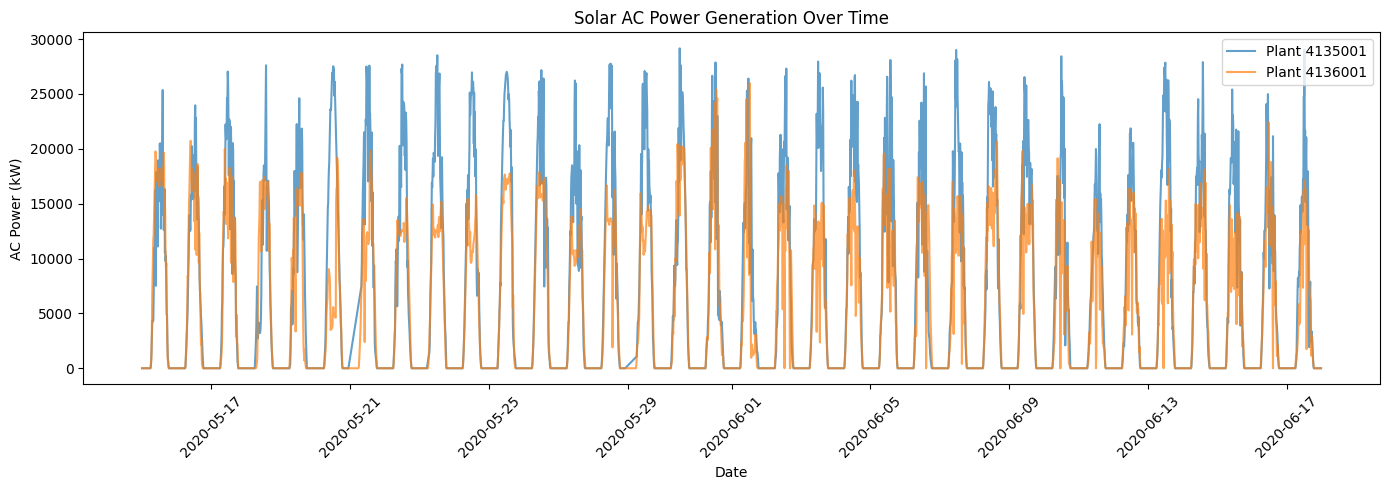

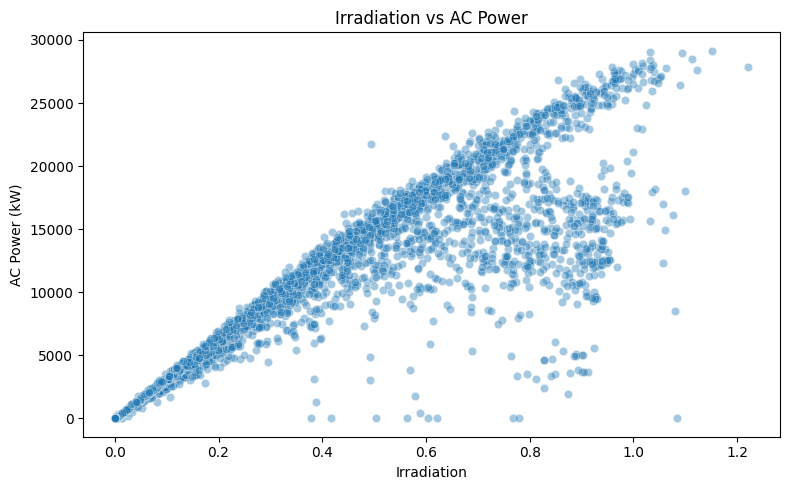

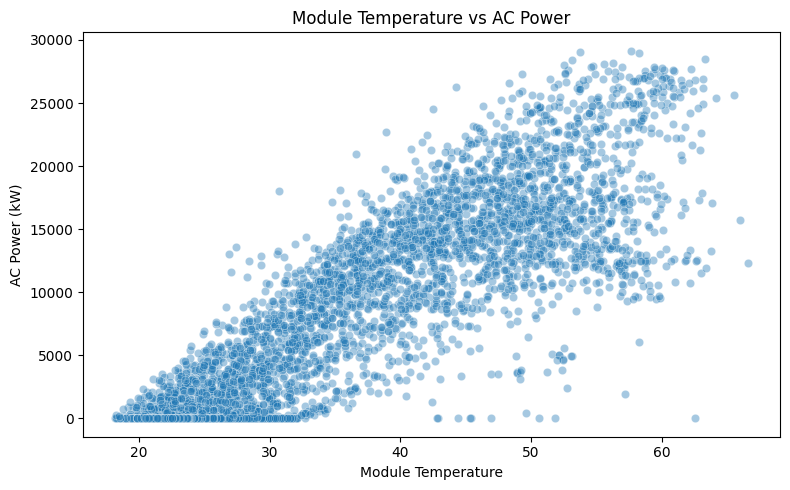

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: AC power over time
plt.figure(figsize=(14, 5))

for plant_id in solar_data["PLANT_ID"].unique():
    plant = solar_data[solar_data["PLANT_ID"] == plant_id]
    plt.plot(
        plant["DATE_TIME"],
        plant["AC_POWER"],
        label=f"Plant {plant_id}",
        alpha=0.7
    )

plt.title("Solar AC Power Generation Over Time")
plt.xlabel("Date")
plt.ylabel("AC Power (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Graph 2: Irradiation vs AC power
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=solar_data,
    x="IRRADIATION",
    y="AC_POWER",
    alpha=0.4
)

plt.title("Irradiation vs AC Power")
plt.xlabel("Irradiation")
plt.ylabel("AC Power (kW)")
plt.tight_layout()
plt.show()


# Graph 3: Module temperature vs AC power
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=solar_data,
    x="MODULE_TEMPERATURE",
    y="AC_POWER",
    alpha=0.4
)

plt.title("Module Temperature vs AC Power")
plt.xlabel("Module Temperature")
plt.ylabel("AC Power (kW)")
plt.tight_layout()
plt.show()

In [11]:
print(solar_data[
    ["AC_POWER", "IRRADIATION",
     "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]
].corr())

                     AC_POWER  IRRADIATION  AMBIENT_TEMPERATURE  \
AC_POWER             1.000000     0.938184             0.593164   
IRRADIATION          0.938184     1.000000             0.654558   
AMBIENT_TEMPERATURE  0.593164     0.654558             1.000000   
MODULE_TEMPERATURE   0.903046     0.950708             0.818020   

                     MODULE_TEMPERATURE  
AC_POWER                       0.903046  
IRRADIATION                    0.950708  
AMBIENT_TEMPERATURE            0.818020  
MODULE_TEMPERATURE             1.000000  


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Select our input features (X)
X = solar_data[
    ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]
]

# 2. Select our prediction target (y)
y = solar_data["AC_POWER"]

# 3. Create a chronological 80/20 split
timestamps = np.sort(solar_data["DATE_TIME"].unique())
split_index = int(len(timestamps) * 0.8)
cutoff = timestamps[split_index]

train_mask = solar_data["DATE_TIME"] < cutoff

X_train = X[train_mask]
X_test = X[~train_mask]

y_train = y[train_mask]
y_test = y[~train_mask]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training ends:", solar_data.loc[train_mask, "DATE_TIME"].max())
print("Testing begins:", solar_data.loc[~train_mask, "DATE_TIME"].min())

# 4. Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Make predictions
predictions = model.predict(X_test)

# 6. Evaluate the model
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("\nLINEAR REGRESSION RESULTS")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

Training observations: 5112
Testing observations: 1304
Training ends: 2020-06-11 04:30:00
Testing begins: 2020-06-11 04:45:00

LINEAR REGRESSION RESULTS
MAE: 1610.3548812440908
MSE: 5579378.546282791
RMSE: 2362.0708173725
R-squared: 0.8813127915103498


In [15]:
# Recreate our Linear Regression predictions

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Linear Regression predictions restored!")

Linear Regression predictions restored!


In [16]:
# STEP 7: Polynomial and Ridge Regression

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge

# Store results for comparison
results = []

# Record our existing Linear Regression results
results.append({
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred)
})

# 1. Polynomial Regression
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

polynomial_model.fit(X_train, y_train)
poly_pred = polynomial_model.predict(X_test)

results.append({
    "Model": "Polynomial Regression",
    "MAE": mean_absolute_error(y_test, poly_pred),
    "MSE": mean_squared_error(y_test, poly_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, poly_pred)),
    "R2": r2_score(y_test, poly_pred)
})

# 2. Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

results.append({
    "Model": "Ridge Regression",
    "MAE": mean_absolute_error(y_test, ridge_pred),
    "MSE": mean_squared_error(y_test, ridge_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, ridge_pred)),
    "R2": r2_score(y_test, ridge_pred)
})

# Display comparison
comparison = pd.DataFrame(results)

print(comparison.round(3).to_string(index=False))

                Model      MAE         MSE     RMSE    R2
    Linear Regression 1610.355 5579378.546 2362.071 0.881
Polynomial Regression  780.867 2957769.450 1719.817 0.937
     Ridge Regression 1609.949 5576207.094 2361.399 0.881


In [17]:
# STEP 8: KNN and MLP Regression

from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. KNN Regression
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

results.append({
    "Model": "KNN Regression",
    "MAE": mean_absolute_error(y_test, knn_pred),
    "MSE": mean_squared_error(y_test, knn_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, knn_pred)),
    "R2": r2_score(y_test, knn_pred)
})

# 2. MLP Regression (Neural Network)
mlp_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
)

mlp_model.fit(X_train, y_train)
mlp_pred = mlp_model.predict(X_test)

results.append({
    "Model": "MLP Regression",
    "MAE": mean_absolute_error(y_test, mlp_pred),
    "MSE": mean_squared_error(y_test, mlp_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, mlp_pred)),
    "R2": r2_score(y_test, mlp_pred)
})

# Display all four models
comparison = pd.DataFrame(results)

print("FINAL REGRESSION MODEL COMPARISON")
print(comparison.round(3).to_string(index=False))

FINAL REGRESSION MODEL COMPARISON
                Model      MAE         MSE     RMSE    R2
    Linear Regression 1610.355 5579378.546 2362.071 0.881
Polynomial Regression  780.867 2957769.450 1719.817 0.937
     Ridge Regression 1609.949 5576207.094 2361.399 0.881
       KNN Regression  698.795 2973292.383 1724.324 0.937
       MLP Regression  804.998 2962976.597 1721.330 0.937


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [18]:
# STEP 9: Inverter-level outlier detection

# Work with the original inverter-level generation data
inverter_data = generation.copy()

# Calculate Q1, Q3 and IQR for each plant and timestamp
groups = inverter_data.groupby(
    ["DATE_TIME", "PLANT_ID"]
)["AC_POWER"]

q1 = groups.transform(lambda x: x.quantile(0.25))
q3 = groups.transform(lambda x: x.quantile(0.75))

iqr = q3 - q1

# Identify unusually low inverter readings
inverter_data["IQR_OUTLIER"] = (
    inverter_data["AC_POWER"] < (q1 - 1.5 * iqr)
)

# Calculate Z-scores within each plant and timestamp
group_mean = groups.transform("mean")
group_std = groups.transform("std")

inverter_data["Z_SCORE"] = (
    (inverter_data["AC_POWER"] - group_mean) /
    group_std.replace(0, np.nan)
)

# Identify readings more than 2 standard deviations below the mean
inverter_data["Z_OUTLIER"] = (
    inverter_data["Z_SCORE"] < -2
)

# Display results
print("IQR outlier readings:",
      inverter_data["IQR_OUTLIER"].sum())

print("Z-score outlier readings:",
      inverter_data["Z_OUTLIER"].sum())

print("\nPotential under-performing inverter readings:")
print(
    inverter_data[
        inverter_data["IQR_OUTLIER"] |
        inverter_data["Z_OUTLIER"]
    ][
        ["DATE_TIME", "PLANT_ID", "SOURCE_KEY",
         "AC_POWER", "Z_SCORE",
         "IQR_OUTLIER", "Z_OUTLIER"]
    ].head(15)
)

IQR outlier readings: 3959
Z-score outlier readings: 3128

Potential under-performing inverter readings:
              DATE_TIME  PLANT_ID       SOURCE_KEY    AC_POWER   Z_SCORE  \
515 2020-05-15 06:00:00   4135001  VHMLBKoKgIrUVDU    0.000000 -3.150753   
531 2020-05-15 06:15:00   4135001  1BY6WEcLGh8j5v7   26.862500 -0.264729   
536 2020-05-15 06:15:00   4135001  VHMLBKoKgIrUVDU    5.912500 -4.249775   
551 2020-05-15 06:15:00   4135001  zVJPv84UY57bAof   26.842857 -0.268466   
552 2020-05-15 06:30:00   4135001  1BY6WEcLGh8j5v7   60.685714 -1.363584   
563 2020-05-15 06:30:00   4135001  bvBOhCH3iADSZry   60.771429 -1.345864   
573 2020-05-15 06:30:00   4135001  zVJPv84UY57bAof   59.550000 -1.598374   
595 2020-05-15 06:45:00   4135001  zVJPv84UY57bAof  113.457143 -2.432797   
596 2020-05-15 07:00:00   4135001  1BY6WEcLGh8j5v7  170.014286 -1.792848   
607 2020-05-15 07:00:00   4135001  bvBOhCH3iADSZry  170.500000 -1.731513   
617 2020-05-15 07:00:00   4135001  zVJPv84UY57bAof  162.675

In [19]:
# Compare how many readings each method flags
print("Total inverter readings:", len(inverter_data))

print("\nIQR outlier percentage:",
      round(inverter_data["IQR_OUTLIER"].mean() * 100, 2), "%")

print("Z-score outlier percentage:",
      round(inverter_data["Z_OUTLIER"].mean() * 100, 2), "%")

# Count how many readings both methods agree on
both_methods = (
    inverter_data["IQR_OUTLIER"] &
    inverter_data["Z_OUTLIER"]
).sum()

print("\nFlagged by BOTH methods:", both_methods)

# Count readings flagged by only one method
print("IQR only:",
      (inverter_data["IQR_OUTLIER"] &
       ~inverter_data["Z_OUTLIER"]).sum())

print("Z-score only:",
      (~inverter_data["IQR_OUTLIER"] &
       inverter_data["Z_OUTLIER"]).sum())

Total inverter readings: 136476

IQR outlier percentage: 2.9 %
Z-score outlier percentage: 2.29 %

Flagged by BOTH methods: 2737
IQR only: 1222
Z-score only: 391


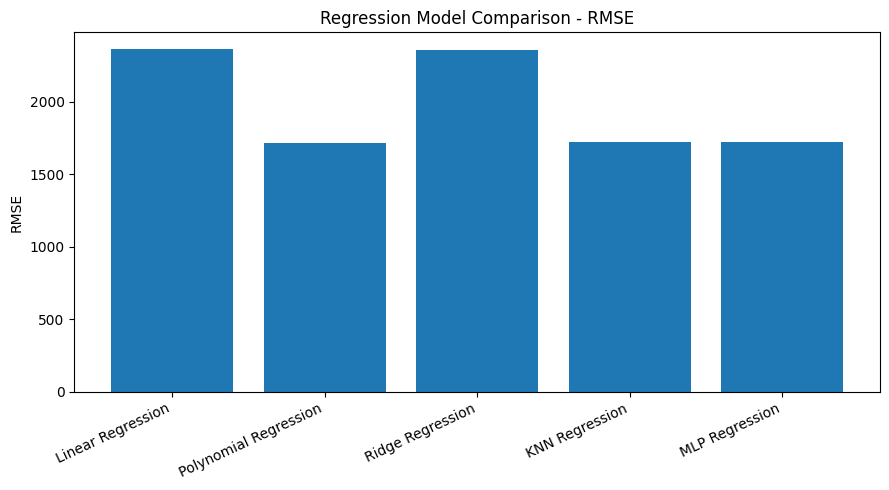

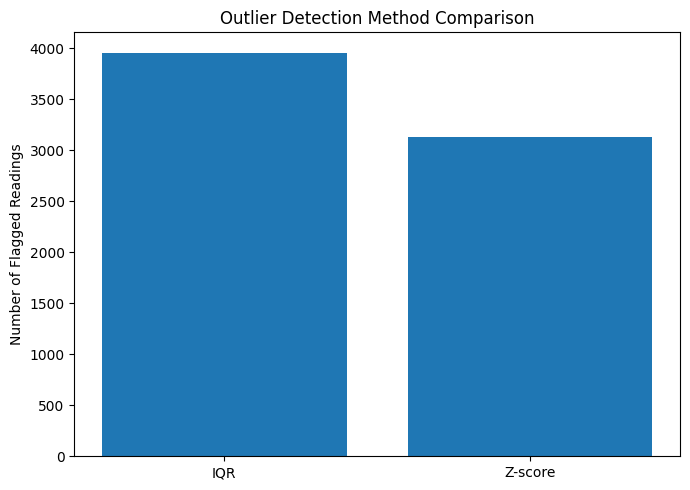

All project results saved successfully!

Files created:
outlier_summary.csv
model_comparison.csv
model_comparison_rmse.png
outlier_comparison.png
flagged_inverter_readings.csv


In [20]:
import os
import matplotlib.pyplot as plt

# Create a folder for project results
os.makedirs("results", exist_ok=True)

# 1. Save model comparison table
comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

# 2. Save outlier detection summary
outlier_summary = pd.DataFrame({
    "Method": ["IQR", "Z-score"],
    "Outlier_Count": [
        inverter_data["IQR_OUTLIER"].sum(),
        inverter_data["Z_OUTLIER"].sum()
    ],
    "Percentage": [
        inverter_data["IQR_OUTLIER"].mean() * 100,
        inverter_data["Z_OUTLIER"].mean() * 100
    ]
})

outlier_summary.to_csv(
    "results/outlier_summary.csv",
    index=False
)

# 3. Save flagged inverter readings
flagged_readings = inverter_data[
    inverter_data["IQR_OUTLIER"] |
    inverter_data["Z_OUTLIER"]
]

flagged_readings.to_csv(
    "results/flagged_inverter_readings.csv",
    index=False
)

# 4. Plot model comparison (RMSE)
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.title("Regression Model Comparison - RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("results/model_comparison_rmse.png", dpi=300)
plt.show()

# 5. Plot outlier detection comparison
plt.figure(figsize=(7, 5))
plt.bar(
    outlier_summary["Method"],
    outlier_summary["Outlier_Count"]
)
plt.title("Outlier Detection Method Comparison")
plt.ylabel("Number of Flagged Readings")
plt.tight_layout()
plt.savefig("results/outlier_comparison.png", dpi=300)
plt.show()

print("All project results saved successfully!")

print("\nFiles created:")
for filename in os.listdir("results"):
    print(filename)